In [1]:
%load_ext autoreload
%autoreload 2

# 测试动量单因子 `MomentumFactor`

In [2]:
from factors import presets
from factors.exploration import xray
from factors.library.basic import MomentumFactor
from factors.scanning import (
    EvaluationResult, join_candidates_sequences, run_scan, 
    gen_candidate_grid, precompute_shared_factors
)
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
import pandas as pd
from collections.abc import Mapping
from typing import Any
from dataclasses import replace
import datetime

In [3]:
# build research dataset and data facade
end_date=datetime.date(2024, 12, 31)
dataset, facade = presets.build_dataset_with_facade(sources=['main_panel', 'term_structure'])

【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\A_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AD_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AG_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AL_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AO_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AP_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables\AU_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: D:\量化策略\CTA策略\early-bird-alpha\db\derived\master_tables

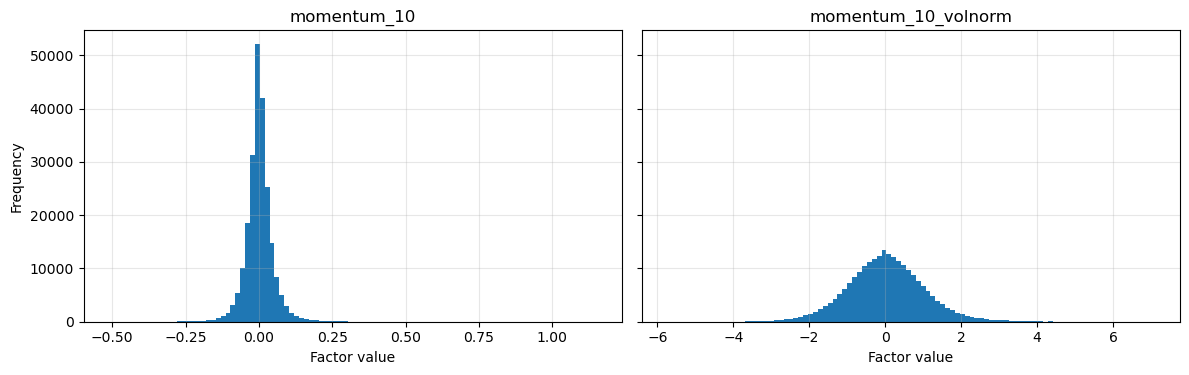

In [4]:
# calculate momentum factor, compare raw momentum vs. volatilit-normalized momentum
r = 10 # set lookback parameter
mom_raw = MomentumFactor(r, False,)
mom_norm = MomentumFactor(r, True, vol_lookback=60, vol_min_periods=10)

mom_raw_values = mom_raw.compute(dataset.main_panel)
mom_norm_values = mom_norm.compute(dataset.main_panel)

_ = xray.plot_hist(mom_raw_values, mom_norm_values, bins=100)

## Evaluation statistics

## Run diagnostic portfolio experiment, with parameter scanning for `MomentumFactor`

In [5]:
# Set factor parameter grids and precompute factor values
grid_norm = {'volnorm': [True], 'lookback': range(5, 65, 5), 
             'vol_lookback': range(10, 60, 20), 'vol_min_periods': [10]}

grid_raw = {'volnorm': [False], 'lookback': range(5, 65, 5)}
data_norm = precompute_shared_factors(
    MomentumFactor, grid_norm, dataset.main_panel, print_out=False
)
data_raw = precompute_shared_factors(
    MomentumFactor, grid_raw, dataset.main_panel, print_out=False
)
data = data_norm | data_raw

# Set experiment parameter grid
experiment_params = {'h': range(5, 65, 5)}
param_grid_momnorm = {**grid_norm, **experiment_params}
param_grid_momraw = {**grid_raw, **experiment_params}

# Generate parameter scanning candidates
cands_momnorm = gen_candidate_grid(param_grid_momnorm)
cands_momraw = gen_candidate_grid(param_grid_momraw)
cands = join_candidates_sequences(cands_momnorm, cands_momraw)

# Define evaluation function, here choose HarvestProfile=market_rank_ls（which 
# belongs to the cross-sectional-market-neutral strategy）
# Choose sharpe and cagr as evaluation metrics
def evaluate_mrls(params: Mapping[str, Any]) -> EvaluationResult:
    if params['volnorm'] == True:
        key = (True, params['lookback'], params['vol_lookback'], 
               params['vol_min_periods'])
    else:
        key = (False, params['lookback'])
    signal = replace(presets.base_signal, values=data[key])
    rebalance = replace(presets.base_rebalance_config, interval=params['h'])
    spec = replace(presets.mrls_base_spec, rebalance=rebalance)

    runner = DiagnosticPortfolioExperimentRunner(
        signal=signal, dataset=dataset, spec=spec)
    result = runner.run()
    metrics = {'sharpe': float(result.performance.loc['proxy_net', 'sharpe']), # type: ignore
               'cagr': float(result.performance.loc['proxy_net', 'cagr'])} # type: ignore
    return EvaluationResult(metrics=metrics, warnings=result.warnings)

result = run_scan(
    evaluate_func=evaluate_mrls,
    candidates=cands,
    error_policy='raise',
    progress_bar=True, 
    desc='scanning params'
)



scanning params: 100%|██████████| 576/576 [06:51<00:00,  1.40it/s]


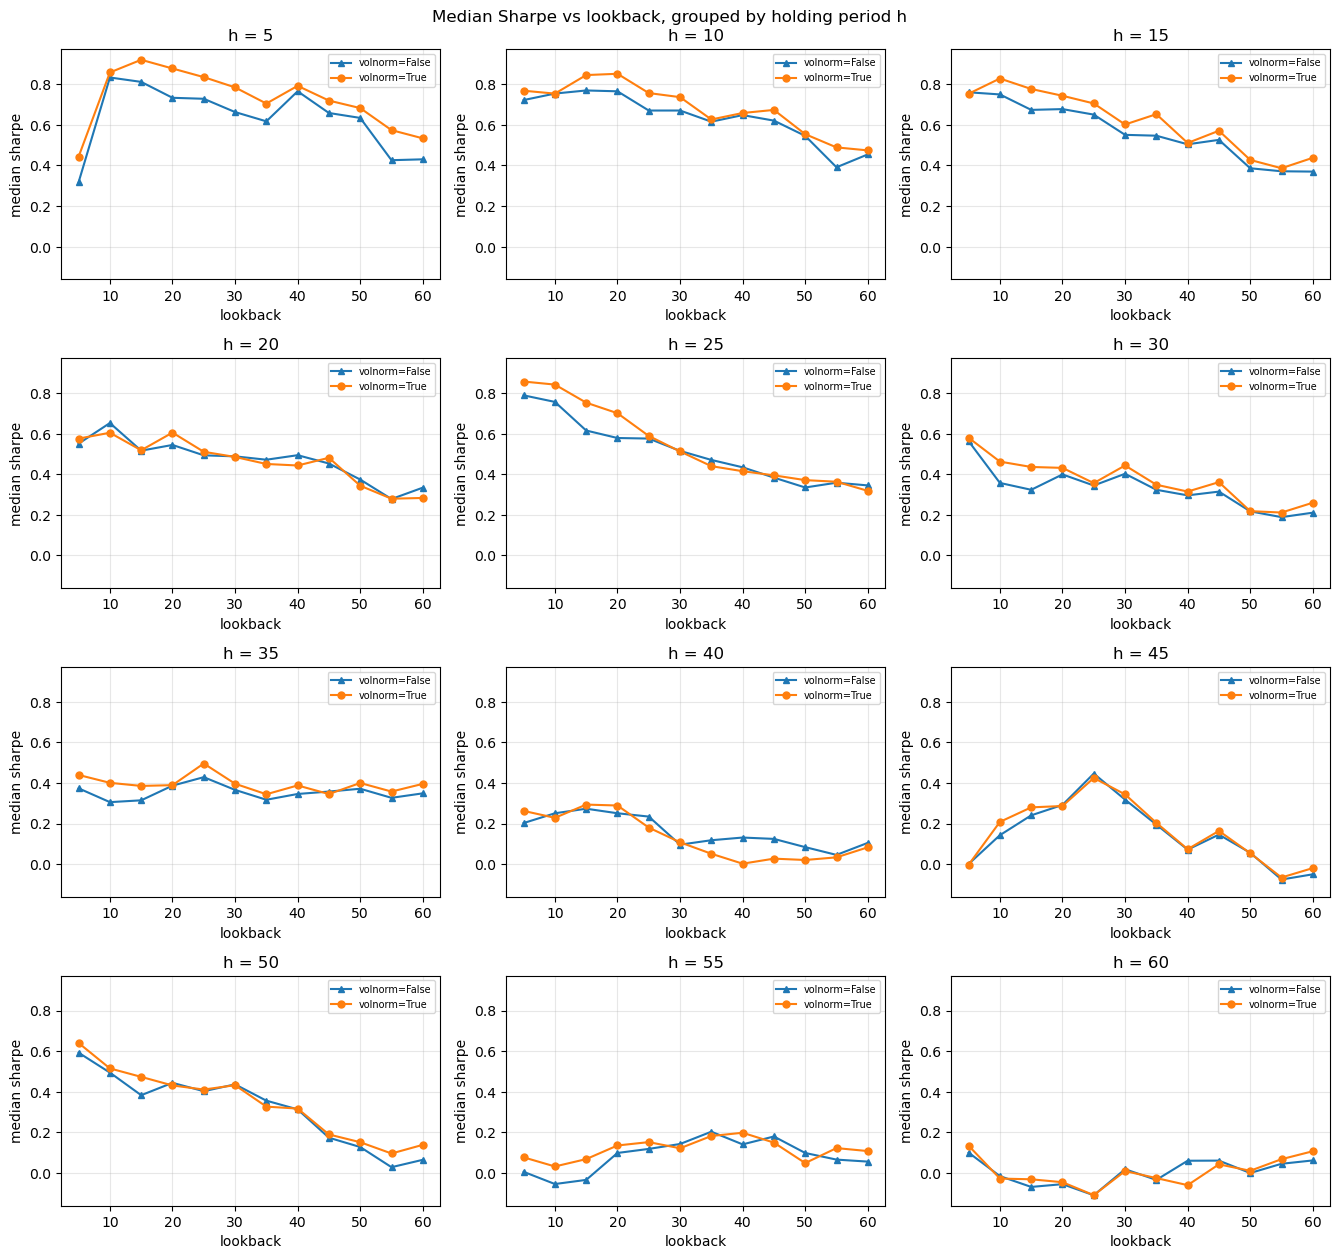

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

df = pd.concat([result.eval_metrics, result.candidate_params], axis=1)
df = df.groupby(['volnorm', 'lookback', 'h']).median()['sharpe']
df.unstack(level=0)

# df has MultiIndex (volnorm, lookback, h) -> median sharpe
plot_df = df.reset_index()
hs = sorted(plot_df['h'].unique())
ncols = 3
nrows = int(np.ceil(len(hs) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.5 * ncols, 3.2 * nrows),
    sharex=True, sharey=True,
)
axes = np.atleast_1d(axes).ravel()

for ax, h in zip(axes, hs):
    sub_h = plot_df[plot_df['h'] == h]
    for volnorm, grp in sub_h.groupby('volnorm'):
        grp = grp.sort_values('lookback')
        ax.plot(
            grp['lookback'], grp['sharpe'],
            marker='o' if volnorm else '^',
            linestyle='-',
            markersize=5,
            label='volnorm=True' if volnorm else 'volnorm=False',
        )
    ax.set_title(f'h = {h}')
    ax.set_xlabel('lookback')
    ax.set_ylabel('median sharpe')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)
    # sharex/sharey hides subplots axis labels，force it to show 
    ax.tick_params(labelbottom=True, labelleft=True)

# close redundant subplots
for ax in axes[len(hs):]:
    ax.set_visible(False)

fig.suptitle('Median Sharpe vs lookback, grouped by holding period h')
fig.tight_layout()
plt.show()

volnorm=True: best (h, lookback)=(5, 15), sharpe=0.9207
volnorm=False: best (h, lookback)=(5, 10), sharpe=0.8335


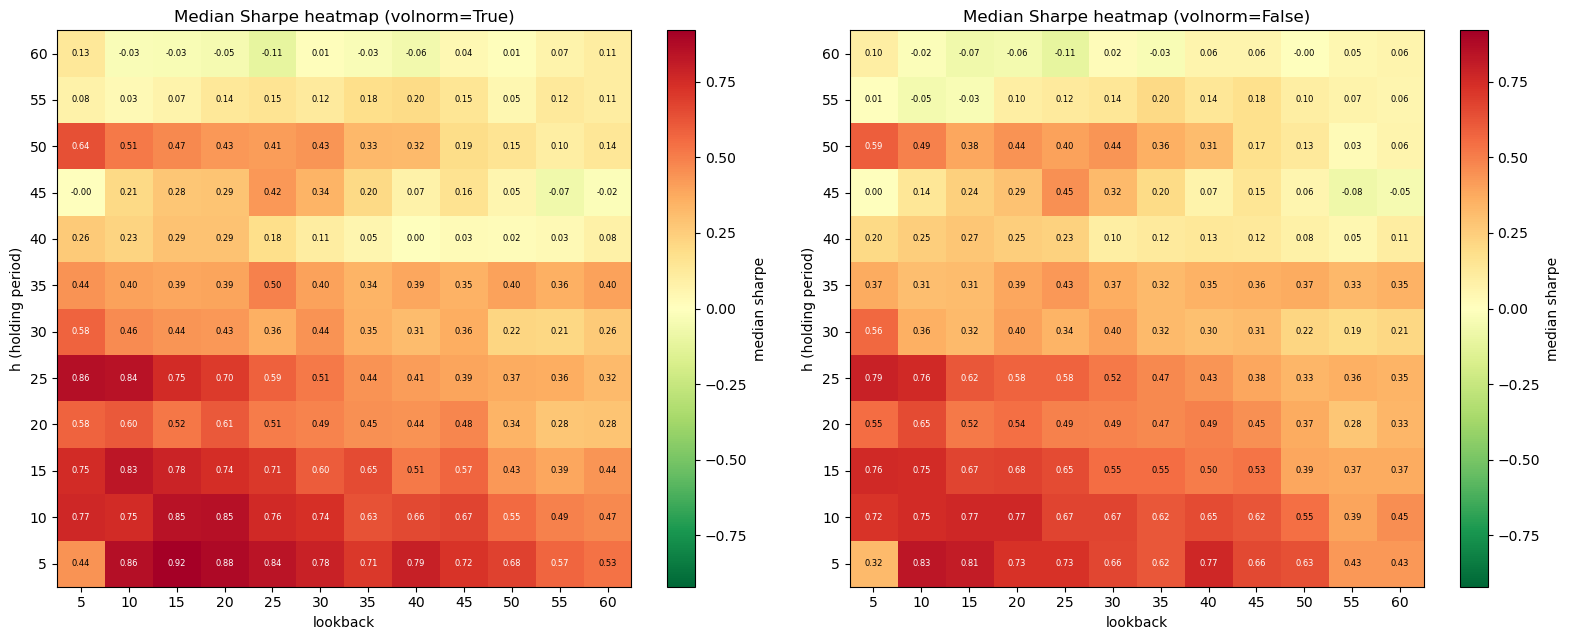

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 全局色标范围，左右两图共用，避免因各自归一化导致视觉不可比
vabs = float(np.nanmax(np.abs(plot_df['sharpe'].values)))

for ax, vn in zip(axes, [True, False]):
    heat = (
        plot_df[plot_df['volnorm'] == vn]
        .pivot(index='h', columns='lookback', values='sharpe')
        .sort_index()
        .sort_index(axis=1)
    )

    im = ax.imshow(
        heat.values, aspect='auto', origin='lower', cmap='RdYlGn_r',
        vmin=-vabs, vmax=vabs,
    )
    ax.set_xticks(range(len(heat.columns)), heat.columns)
    ax.set_yticks(range(len(heat.index)), heat.index)
    ax.set_xlabel('lookback')
    ax.set_ylabel('h (holding period)')
    ax.set_title(f'Median Sharpe heatmap (volnorm={vn})')
    fig.colorbar(im, ax=ax, label='median sharpe')

    # 数值标注：依据 |value| / vabs 决定黑白
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = heat.values[i, j]
            if np.isnan(v):
                continue
            ax.text(
                j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                color='black' if abs(v) < 0.6 * vabs else 'white',
            )

    best = heat.stack().idxmax()
    print(f'volnorm={vn}: best (h, lookback)={best}, sharpe={heat.loc[best[0], best[1]]:.4f}')

fig.tight_layout()
plt.show()
